# Salon Experiment & Causal Analysis — Difference-in-Differences

> **Synthetic data:** The outlets, clients, appointments, revenues, and policy assignments are fictional. The generator includes an artificial post-policy revenue multiplier for testing; estimates here are calculations on simulated data, not evidence about a real policy.

The analysis uses outlet-month outcomes and outlet and month fixed effects to examine the policy that starts **2026-07-01**. The primary comparison is November 2025–June 2026 versus July–August 2026. September–October is reported separately because it overlaps the A/B experiment. Raw CSVs are read only.

## 1. Design, outcomes, and interpretation

**Assignment:** North and South are treated; East and West are controls. Region-level policy status is mapped to 22 outlets (11 per group).

**Primary window:** Pre-policy = November 2025–June 2026; primary post-policy = July–August 2026. **Sensitivity window:** September–October 2026, when the client-level A/B experiment also operates.

**Outcomes:** Monthly outlet service revenue (sum of net service revenue) and appointment count (all appointment statuses). Each outlet-month is one row; no appointment row is treated as an independent experiment unit. Revenue is expected to be policy-sensitive by construction; appointment volume is a descriptive secondary outcome.

**Model:** Two-way fixed effects regression with outlet and calendar-month effects; the Treated × Post coefficient is the DiD estimate. Uncertainty is clustered by region, the assignment level, but there are only **four regions (two treated, two controls)**. With so few clusters, conventional cluster-robust p-values and intervals are unreliable and should be treated as diagnostics.

**Interpretation depends on assumptions:** DiD requires parallel trends in the absence of the policy, no differential concurrent changes, stable measurement and composition, no spillovers, and no anticipation. Pre-period plots can reveal departures but cannot prove the counterfactual assumption. The 4% multiplier is an artificial generator setting, not an empirical finding.

## 2. Load raw data and validate the policy design

The setup locates the project root and loads the tables needed for the outlet-month panel and A/B overlap check. It validates dates, outlet coverage, region labels, and treatment coding before estimation.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (root for root in candidate_roots if (root / "data" / "raw").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate data/raw. Start Jupyter in the project root or notebooks/."
    )
RAW_DIR = PROJECT_ROOT / "data" / "raw"
required_files = [
    "appointments.csv",
    "outlets.csv",
    "did_outlet_policy.csv",
    "experiment_assignments.csv",
]
missing = [name for name in required_files if not (RAW_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing required raw CSVs: {missing}")

appointments = pd.read_csv(RAW_DIR / "appointments.csv")
outlets = pd.read_csv(RAW_DIR / "outlets.csv")
policy = pd.read_csv(RAW_DIR / "did_outlet_policy.csv")
assignments = pd.read_csv(RAW_DIR / "experiment_assignments.csv")
appointments["appointment_date"] = pd.to_datetime(
    appointments["appointment_date"], errors="coerce"
)
assignments["experiment_start_date"] = pd.to_datetime(
    assignments["experiment_start_date"], errors="coerce"
)

assert appointments["appointment_date"].notna().all()
assert outlets["outlet_id"].is_unique and len(outlets) == 22
assert policy["outlet_id"].is_unique and len(policy) == 22
assert set(policy["outlet_id"]) == set(outlets["outlet_id"])
assert policy["policy_start_date"].eq("2026-07-01").all()
assert policy["region"].isin(["North", "South", "East", "West"]).all()
assert policy.loc[policy["region"].isin(["North", "South"]), "policy_group"].eq("Treated").all()
assert policy.loc[policy["region"].isin(["East", "West"]), "policy_group"].eq("Control").all()
assert policy.loc[policy["region"].isin(["North", "South"]), "is_treated"].eq(1).all()
assert policy.loc[policy["region"].isin(["East", "West"]), "is_treated"].eq(0).all()
assert policy["region"].nunique() == 4
assert policy.groupby("policy_group")["outlet_id"].nunique().to_dict() == {
    "Control": 11, "Treated": 11
}

POLICY_START = pd.Timestamp("2026-07-01")
PRE_START = pd.Timestamp("2025-11-01")
PRE_END = pd.Timestamp("2026-06-30")
PRIMARY_POST_START = pd.Timestamp("2026-07-01")
PRIMARY_POST_END = pd.Timestamp("2026-08-31")
SENSITIVITY_POST_START = pd.Timestamp("2026-09-01")
SENSITIVITY_POST_END = pd.Timestamp("2026-10-31")

print(f"Project root: {PROJECT_ROOT}")
print("Raw CSV files loaded read-only.")
print(f"Policy start: {POLICY_START.date()}")
print("Outlets by policy group:", policy.groupby("policy_group")["outlet_id"].nunique().to_dict())
print("Regions by policy group:", policy.groupby("policy_group")["region"].nunique().to_dict())
print("Regions:", sorted(policy["region"].unique()))

Project root: C:\Users\HP\Desktop\intrenship\salon-causal-analysis
Raw CSV files loaded read-only.
Policy start: 2026-07-01
Outlets by policy group: {'Control': 11, 'Treated': 11}
Regions by policy group: {'Control': 2, 'Treated': 2}
Regions: ['East', 'North', 'South', 'West']


## 3. Construct a complete outlet-month panel

Aggregate appointments to outlet-month service revenue and appointment counts. Fill missing outlet-months with zero so the panel includes all 22 outlets in all 12 months. A month is assigned the first day of its calendar month. The service-revenue outcome is net appointment revenue, not product sales.

In [2]:
panel_source = appointments.merge(
    policy[["outlet_id", "region", "policy_group", "is_treated"]],
    on="outlet_id",
    how="left",
    validate="many_to_one",
)
assert panel_source["policy_group"].notna().all()
panel_source["month"] = (
    panel_source["appointment_date"].dt.to_period("M").dt.to_timestamp()
)
monthly_observed = panel_source.groupby(
    ["outlet_id", "month"], as_index=False
).agg(
    service_revenue=("appointment_revenue", "sum"),
    appointment_count=("appointment_id", "size"),
    completed_count=("appointment_status", lambda values: values.eq("Completed").sum()),
)

all_months = pd.date_range(PRE_START, SENSITIVITY_POST_END, freq="MS")
complete_index = pd.MultiIndex.from_product(
    [outlets["outlet_id"], all_months], names=["outlet_id", "month"]
)
panel = (
    monthly_observed.set_index(["outlet_id", "month"])
    .reindex(complete_index, fill_value=0)
    .reset_index()
    .merge(
        policy[["outlet_id", "region", "policy_group", "is_treated"]],
        on="outlet_id",
        how="left",
        validate="many_to_one",
    )
)
panel["month_label"] = panel["month"].dt.strftime("%Y-%m")
panel["post_primary"] = panel["month"].between(
    PRIMARY_POST_START, PRIMARY_POST_END
).astype(int)
panel["post_sensitivity"] = panel["month"].between(
    PRIMARY_POST_START, SENSITIVITY_POST_END
).astype(int)
panel["post_policy"] = panel["month"].ge(POLICY_START).astype(int)
assert len(panel) == 22 * 12
assert panel.groupby("outlet_id")["month"].nunique().eq(12).all()
assert panel[["service_revenue", "appointment_count"]].ge(0).all().all()

print(f"Balanced outlet-month panel: {len(panel)} rows = 22 outlets × 12 months.")
print("Observed month range:", panel["month"].min().date(), "to", panel["month"].max().date())
display(panel.groupby("policy_group").agg(
    outlets=("outlet_id", "nunique"),
    outlet_months=("month", "size"),
    total_service_revenue=("service_revenue", "sum"),
    total_appointment_rows=("appointment_count", "sum"),
))

Balanced outlet-month panel: 264 rows = 22 outlets × 12 months.
Observed month range: 2025-11-01 to 2026-10-01


,outlets,outlet_months,total_service_revenue,total_appointment_rows
policy_group,,,,
Control,11,132,8143684.04,150910
Treated,11,132,8279144.33,149090


## 4. Pre-policy parallel-trends assessment

Before intervention, compare monthly means per outlet for treated and control groups and the treated-minus-control gap. The month-to-month change in that gap makes differential movements visible. Parallel-looking historical patterns are a useful diagnostic, not proof of parallel counterfactual trends. There are only eight pre-policy months and four assignment regions.

,treated_mean_revenue,control_mean_revenue,revenue_gap_T_minus_C,change_in_revenue_gap,treated_mean_appointments,control_mean_appointments,appointment_gap_T_minus_C,change_in_appointment_gap
month,,,,,,,,
2025-11-01,149560.36,147958.30,1602.07,NaN,2753.82,2758.09,-4.27,NaN
2025-12-01,104594.16,104394.79,199.37,-1402.70,1905.09,1942.18,-37.09,-32.82
2026-01-01,72234.82,72552.57,-317.75,-517.11,1315.09,1346.27,-31.18,5.91
2026-02-01,55470.51,56442.46,-971.95,-654.20,1005.18,1053.09,-47.91,-16.73
2026-03-01,52147.09,53292.63,-1145.54,-173.59,957.36,990.91,-33.55,14.36
2026-04-01,45369.91,46433.60,-1063.68,81.86,828.45,867.82,-39.36,-5.82
2026-05-01,45197.64,44064.33,1133.31,2196.99,817.55,828.36,-10.82,28.55
2026-06-01,40851.21,41381.66,-530.45,-1663.76,741.09,757.55,-16.45,-5.64


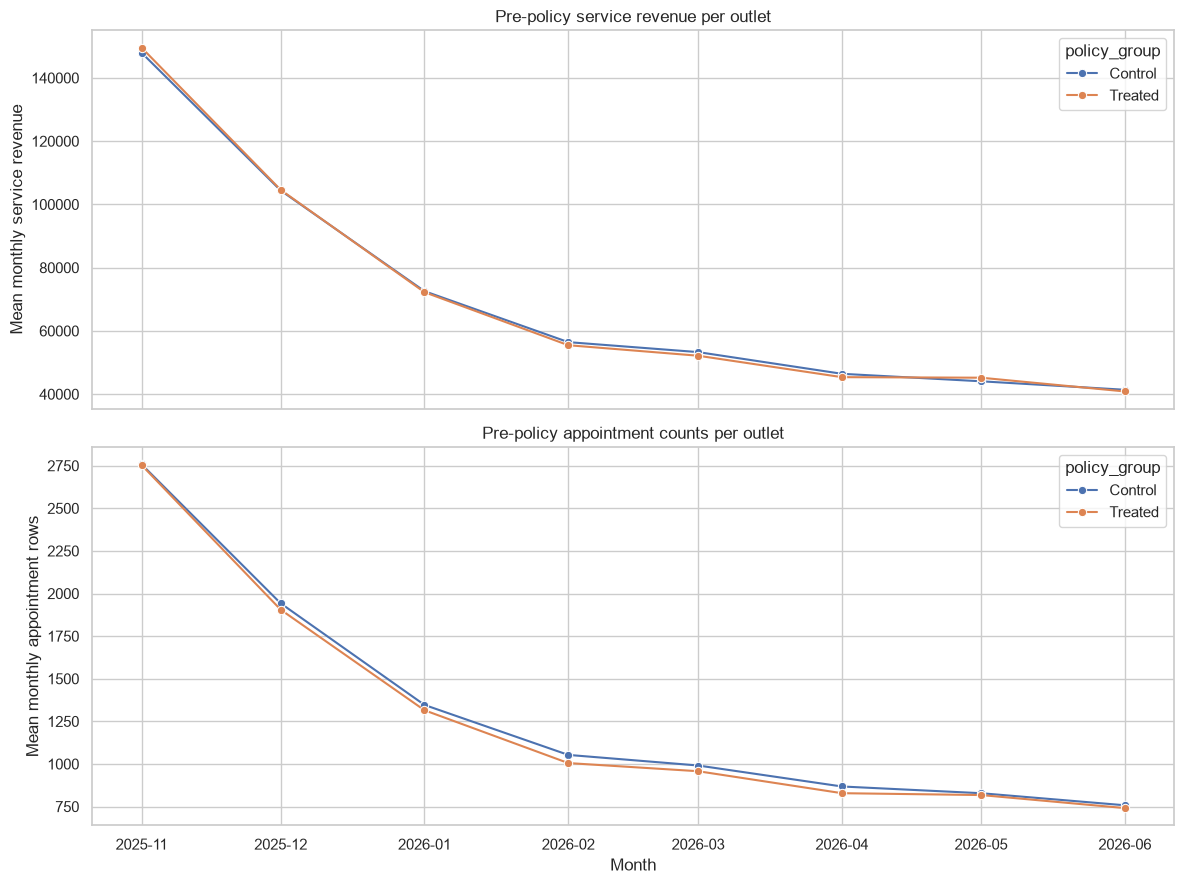

In [3]:
pre_panel = panel.loc[panel["month"].between(PRE_START, PRE_END)].copy()
pre_trends = pre_panel.groupby(["month", "policy_group"]).agg(
    mean_revenue_per_outlet=("service_revenue", "mean"),
    mean_appointments_per_outlet=("appointment_count", "mean"),
).reset_index()

pre_revenue_wide = pre_trends.pivot(
    index="month", columns="policy_group", values="mean_revenue_per_outlet"
)
pre_count_wide = pre_trends.pivot(
    index="month", columns="policy_group", values="mean_appointments_per_outlet"
)
trend_table = pd.DataFrame({
    "treated_mean_revenue": pre_revenue_wide["Treated"],
    "control_mean_revenue": pre_revenue_wide["Control"],
    "revenue_gap_T_minus_C": pre_revenue_wide["Treated"] - pre_revenue_wide["Control"],
    "change_in_revenue_gap": (pre_revenue_wide["Treated"] - pre_revenue_wide["Control"]).diff(),
    "treated_mean_appointments": pre_count_wide["Treated"],
    "control_mean_appointments": pre_count_wide["Control"],
    "appointment_gap_T_minus_C": pre_count_wide["Treated"] - pre_count_wide["Control"],
    "change_in_appointment_gap": (pre_count_wide["Treated"] - pre_count_wide["Control"]).diff(),
})
display(trend_table.round(2))

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
sns.lineplot(data=pre_trends, x="month", y="mean_revenue_per_outlet",
             hue="policy_group", marker="o", ax=axes[0])
axes[0].set(title="Pre-policy service revenue per outlet",
            ylabel="Mean monthly service revenue")
sns.lineplot(data=pre_trends, x="month", y="mean_appointments_per_outlet",
             hue="policy_group", marker="o", ax=axes[1])
axes[1].set(title="Pre-policy appointment counts per outlet",
            xlabel="Month", ylabel="Mean monthly appointment rows")
plt.tight_layout()
plt.show()

### Pre-trend diagnostic summary

The next cell gives a descriptive linear-slope comparison over the pre-period. It is not a decisive parallel-trends test: slope estimates from only eight months and two treated/two control regions are noisy, and failure to detect a difference would not establish parallel trends.

In [4]:
pre_slope_rows = []
pre_panel["month_index"] = (
    (pre_panel["month"].dt.year - PRE_START.year) * 12
    + pre_panel["month"].dt.month - PRE_START.month
)
for outcome in ["service_revenue", "appointment_count"]:
    group_slopes = {}
    for group in ["Treated", "Control"]:
        means = (
            pre_panel.loc[pre_panel["policy_group"].eq(group)]
            .groupby("month_index")[outcome]
            .mean()
        )
        slope = np.polyfit(means.index.to_numpy(), means.to_numpy(), 1)[0]
        group_slopes[group] = slope
    pre_slope_rows.append({
        "outcome": outcome,
        "treated_monthly_slope": group_slopes["Treated"],
        "control_monthly_slope": group_slopes["Control"],
        "slope_difference_T_minus_C": group_slopes["Treated"] - group_slopes["Control"],
    })
display(pd.DataFrame(pre_slope_rows).round(3))
print(
    "Interpret cautiously: visual/slope similarity cannot verify the unobserved "
    "counterfactual parallel-trends assumption."
)

,outcome,treated_monthly_slope,control_monthly_slope,slope_difference_T_minus_C
0,service_revenue,-13593.629,-13442.804,-150.825
1,appointment_count,-250.411,-250.839,0.427


Interpret cautiously: visual/slope similarity cannot verify the unobserved counterfactual parallel-trends assumption.


## 5. Fixed-effects DiD estimation

For each outcome, fit `outcome ~ Treated × Post + outlet fixed effects + month fixed effects`. The interaction coefficient is the additive DiD estimate per outlet-month. Primary analysis excludes September–October; sensitivity analysis extends post through October. We show (a) ordinary OLS intervals as a model-based reference and (b) standard errors clustered by region, the policy-assignment level. With four clusters, the latter remains severely unreliable; do not treat conventional p-values or intervals as strong causal evidence.

Percent effect is the additive DiD estimate divided by the control-group mean outcome during the relevant post months. It is shown only when that denominator is positive and is an approximate scaling, not a separate causal estimand.

In [5]:
def fit_did(data, outcome, post_column, extra_formula_terms=""):
    model_data = data.copy()
    model_data["treated_post"] = (
        model_data["is_treated"] * model_data[post_column]
    )
    formula = f"{outcome} ~ treated_post + C(outlet_id) + C(month_label)"
    if extra_formula_terms:
        formula += " + " + extra_formula_terms
    model = smf.ols(formula, data=model_data).fit()
    # This covariance estimate has only four independent region clusters.
    clustered = model.get_robustcov_results(
        cov_type="cluster",
        groups=model_data["region"],
        use_correction=True,
        df_correction=True,
        use_t=True,
    )
    term_index = model.model.exog_names.index("treated_post")
    coefficient = float(model.params["treated_post"])
    ordinary_ci = model.conf_int().loc["treated_post"].to_numpy(dtype=float)
    cluster_ci = np.asarray(clustered.conf_int())[term_index]
    cluster_p = float(clustered.pvalues[term_index])
    return {
        "model": model,
        "clustered": clustered,
        "coefficient": coefficient,
        "ordinary_ci_low": float(ordinary_ci[0]),
        "ordinary_ci_high": float(ordinary_ci[1]),
        "cluster_ci_low": float(cluster_ci[0]),
        "cluster_ci_high": float(cluster_ci[1]),
        "cluster_p_value": cluster_p,
        "observations": int(model.nobs),
        "regions": int(model_data["region"].nunique()),
        "outlets": int(model_data["outlet_id"].nunique()),
    }

primary_data = panel.loc[
    panel["month"].between(PRE_START, PRIMARY_POST_END)
].copy()
assert set(primary_data.loc[primary_data["post_primary"].eq(1), "month"].dt.month) == {7, 8}
primary_models = {}
primary_rows = []
for outcome in ["service_revenue", "appointment_count"]:
    result = fit_did(primary_data, outcome, "post_primary")
    primary_models[outcome] = result
    control_post_mean = primary_data.loc[
        primary_data["policy_group"].eq("Control")
        & primary_data["post_primary"].eq(1), outcome
    ].mean()
    percent = (
        100 * result["coefficient"] / control_post_mean
        if control_post_mean > 0 else np.nan
    )
    primary_rows.append({
        "outcome": outcome,
        "DiD_estimate": result["coefficient"],
        "ordinary_95CI_low": result["ordinary_ci_low"],
        "ordinary_95CI_high": result["ordinary_ci_high"],
        "region_cluster_95CI_low": result["cluster_ci_low"],
        "region_cluster_95CI_high": result["cluster_ci_high"],
        "region_cluster_p": result["cluster_p_value"],
        "control_post_mean": control_post_mean,
        "approx_percent_of_control_post_mean": percent,
        "outlet_month_rows": result["observations"],
        "regions": result["regions"],
    })
primary_results = pd.DataFrame(primary_rows).set_index("outcome")
display(primary_results.round(3))
print(
    "Primary model periods: Nov 2025-Jun 2026 pre; Jul-Aug 2026 post. "
    "Region-clustered inference uses only four clusters."
)

,DiD_estimate,ordinary_95CI_low,ordinary_95CI_high,region_cluster_95CI_low,region_cluster_95CI_high,region_cluster_p,control_post_mean,approx_percent_of_control_post_mean,outlet_month_rows,regions
outcome,,,,,,,,,,
service_revenue,3558.201,990.657,6125.745,761.479,6354.923,0.027,45890.387,7.754,220,4
appointment_count,40.261,2.736,77.787,-36.057,116.580,0.192,847.500,4.751,220,4


Primary model periods: Nov 2025-Jun 2026 pre; Jul-Aug 2026 post. Region-clustered inference uses only four clusters.


## 6. Event-study style estimates

Estimate treated-by-month interactions with outlet and month fixed effects, omitting June 2026 as the reference month. Each coefficient is the treated-control difference in that month relative to the June difference. Pre-policy coefficients help visualize deviations from a flat relative trend; post-policy coefficients show dynamics but are not independent monthly causal estimates. Bands below use region-clustered covariance and inherit the four-cluster weakness.

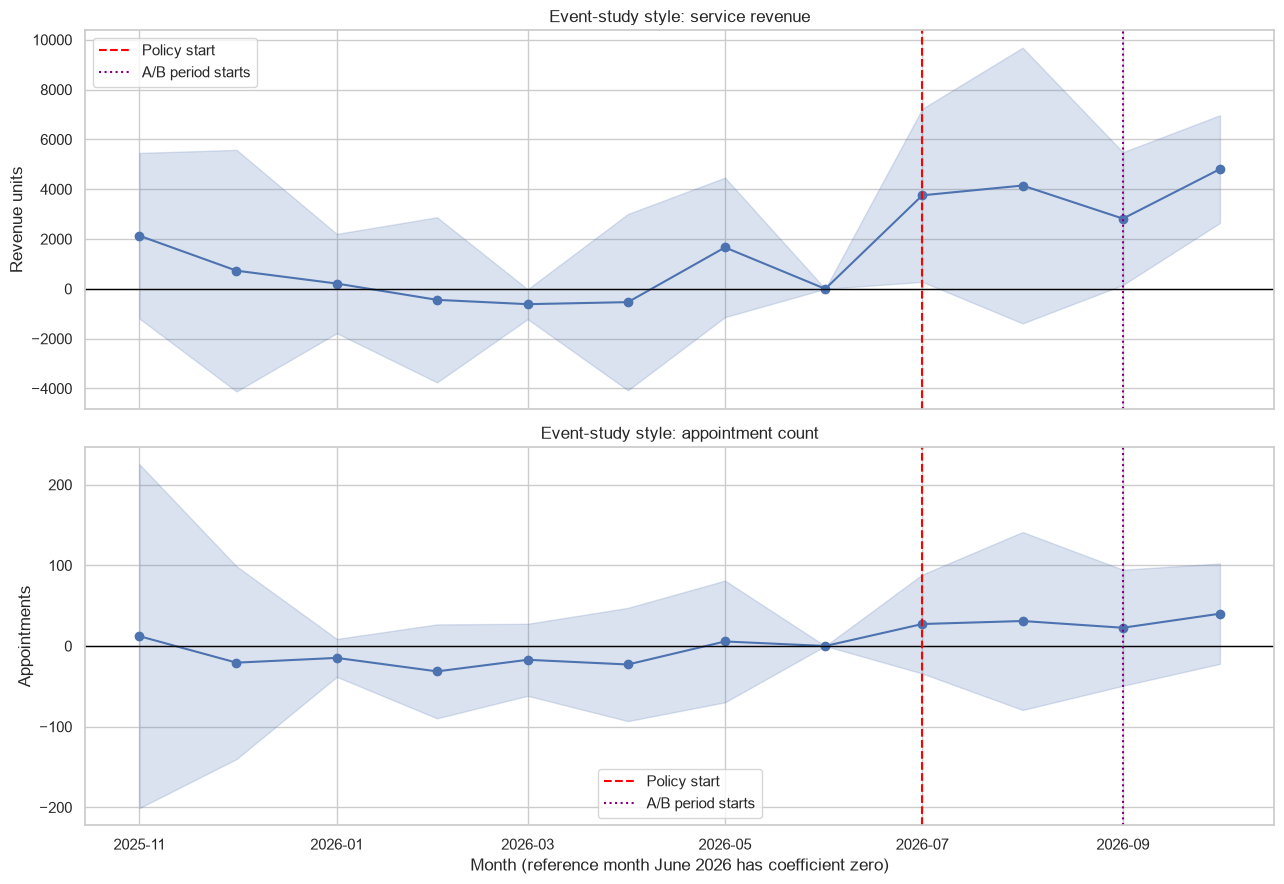

,month,estimate,ci_low,ci_high
0,2025-11,2132.52,-1192.22,5457.26
1,2025-12,729.82,-4118.90,5578.53
2,2026-01,212.70,-1779.79,2205.20
3,2026-02,-441.50,-3756.61,2873.61
4,2026-03,-615.09,-1214.84,-15.34
5,2026-04,-533.23,-4072.52,3006.05
6,2026-05,1663.76,-1136.38,4463.90
11,2026-06,0.00,0.00,0.00
7,2026-07,3755.19,280.02,7230.36
8,2026-08,4148.46,-1386.34,9683.25


In [6]:
def fit_event_study(data, outcome, reference_month="2026-06"):
    event_data = data.copy()
    event_data["event_month"] = event_data["month"].dt.strftime("%Y-%m")
    levels = sorted(event_data["event_month"].unique())
    if reference_month not in levels:
        raise ValueError(f"Reference month {reference_month} is absent.")
    interaction_columns = []
    for level in levels:
        if level == reference_month:
            continue
        column = "treat_month_" + level.replace("-", "_")
        event_data[column] = (
            event_data["is_treated"] * event_data["event_month"].eq(level).astype(int)
        )
        interaction_columns.append(column)
    formula = (
        f"{outcome} ~ " + " + ".join(interaction_columns)
        + " + C(outlet_id) + C(event_month)"
    )
    fitted = smf.ols(formula, data=event_data).fit()
    robust = fitted.get_robustcov_results(
        cov_type="cluster",
        groups=event_data["region"],
        use_correction=True,
        df_correction=True,
        use_t=True,
    )
    names = fitted.model.exog_names
    covariance = np.asarray(robust.cov_params())
    terms = []
    for index, name in enumerate(names):
        if not name.startswith("treat_month_"):
            continue
        month_label = name.removeprefix("treat_month_").replace("_", "-")
        estimate = float(fitted.params.iloc[index])
        se = float(np.sqrt(max(covariance[index, index], 0)))
        critical = stats.t.ppf(0.975, df=event_data["region"].nunique() - 1)
        terms.append({
            "month": pd.Period(month_label, freq="M").to_timestamp(),
            "estimate": estimate,
            "ci_low": estimate - critical * se,
            "ci_high": estimate + critical * se,
        })
    terms.append({
        "month": pd.Period(reference_month, freq="M").to_timestamp(),
        "estimate": 0.0, "ci_low": 0.0, "ci_high": 0.0,
    })
    return pd.DataFrame(terms).sort_values("month"), fitted

event_data = panel.loc[panel["month"].between(PRE_START, SENSITIVITY_POST_END)].copy()
event_revenue, event_revenue_model = fit_event_study(event_data, "service_revenue")
event_counts, event_count_model = fit_event_study(event_data, "appointment_count")

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for ax, frame, title, ylabel in [
    (axes[0], event_revenue, "Event-study style: service revenue", "Revenue units"),
    (axes[1], event_counts, "Event-study style: appointment count", "Appointments"),
]:
    ax.fill_between(frame["month"], frame["ci_low"], frame["ci_high"],
                    alpha=0.2, color=sns.color_palette()[0])
    ax.plot(frame["month"], frame["estimate"], marker="o",
            color=sns.color_palette()[0])
    ax.axhline(0, color="black", linewidth=1)
    ax.axvline(POLICY_START, color="red", linestyle="--", label="Policy start")
    ax.axvline(pd.Timestamp("2026-09-01"), color="purple", linestyle=":",
               label="A/B period starts")
    ax.set(title=title, ylabel=ylabel)
    ax.legend()
axes[1].set_xlabel("Month (reference month June 2026 has coefficient zero)")
plt.tight_layout()
plt.show()

display(event_revenue.assign(month=event_revenue["month"].dt.strftime("%Y-%m")).round(2))

## 7. September–October sensitivity analysis

The A/B experiment overlaps policy post-treatment in September and October. As a sensitivity analysis, first estimate an extended July–October post-period without adjustment. Then add an outlet-month measure of the share of linked appointment rows belonging to A/B Treatment-assigned clients. This exposure share is only available in September–October and is an imperfect adjustment: appointments are not randomized units, the exposure measure may be affected by composition, and client assignment occurs within the same outlets. Therefore the adjusted result is exploratory and should not be read as a clean policy effect.

In [7]:
# Map client-level experiment assignment onto linked appointment rows.
appointment_with_ab = appointments.merge(
    assignments[["client_id", "assignment_group"]],
    on="client_id",
    how="left",
    validate="many_to_one",
)
appointment_with_ab["month"] = (
    appointment_with_ab["appointment_date"].dt.to_period("M").dt.to_timestamp()
)
linked = appointment_with_ab.loc[appointment_with_ab["client_id"].notna()].copy()
ab_exposure = linked.groupby(["outlet_id", "month"]).agg(
    linked_appointment_rows=("appointment_id", "size"),
    ab_treatment_appointment_rows=(
        "assignment_group", lambda values: values.eq("Treatment").sum()
    ),
).reset_index()
ab_exposure["ab_treatment_share"] = np.divide(
    ab_exposure["ab_treatment_appointment_rows"],
    ab_exposure["linked_appointment_rows"],
    out=np.zeros(len(ab_exposure), dtype=float),
    where=ab_exposure["linked_appointment_rows"].to_numpy() > 0,
)
sensitivity_panel = panel.merge(
    ab_exposure[["outlet_id", "month", "ab_treatment_share"]],
    on=["outlet_id", "month"],
    how="left",
)
sensitivity_panel["ab_treatment_share"] = sensitivity_panel["ab_treatment_share"].fillna(0)
sensitivity_data = sensitivity_panel.loc[
    sensitivity_panel["month"].between(PRE_START, SENSITIVITY_POST_END)
].copy()

sensitivity_rows = []
sensitivity_models = {}
for outcome in ["service_revenue", "appointment_count"]:
    unadjusted = fit_did(sensitivity_data, outcome, "post_sensitivity")
    adjusted = fit_did(
        sensitivity_data, outcome, "post_sensitivity",
        extra_formula_terms="ab_treatment_share",
    )
    sensitivity_models[(outcome, "unadjusted")] = unadjusted
    sensitivity_models[(outcome, "A/B exposure adjusted")] = adjusted
    sensitivity_rows.extend([
        {
            "outcome": outcome, "specification": "Unadjusted extended post",
            "DiD_estimate": unadjusted["coefficient"],
            "region_cluster_95CI_low": unadjusted["cluster_ci_low"],
            "region_cluster_95CI_high": unadjusted["cluster_ci_high"],
            "region_cluster_p": unadjusted["cluster_p_value"],
        },
        {
            "outcome": outcome, "specification": "Exploratory A/B exposure adjusted",
            "DiD_estimate": adjusted["coefficient"],
            "region_cluster_95CI_low": adjusted["cluster_ci_low"],
            "region_cluster_95CI_high": adjusted["cluster_ci_high"],
            "region_cluster_p": adjusted["cluster_p_value"],
        },
    ])
sensitivity_results = pd.DataFrame(sensitivity_rows).set_index(
    ["outcome", "specification"]
)
display(sensitivity_results.round(3))
print(
    "Sensitivity period: July-October 2026 post; September-October overlaps A/B. "
    "The exposure-adjusted specification is exploratory, not a validated correction."
)

DiD_estimate  \
outcome           specification                                     
service_revenue   Unadjusted extended post               3489.126   
                  Exploratory A/B exposure adjusted      3531.543   
appointment_count Unadjusted extended post                 41.375   
                  Exploratory A/B exposure adjusted        40.852   

                                                     region_cluster_95CI_low  \
outcome           specification                                                
service_revenue   Unadjusted extended post                          1646.767   
                  Exploratory A/B exposure adjusted                 1947.506   
appointment_count Unadjusted extended post                           -26.505   
                  Exploratory A/B exposure adjusted                  -26.967   

                                                     region_cluster_95CI_high  \
outcome           specification                                                 
service_revenue   Unadjusted extended post                           5331.486   
                  Exploratory A/B exposure adjusted                  5115.580   
appointment_count Unadjusted extended post                            109.255   
                  Exploratory A/B exposure adjusted                   108.671   

                                                     region_cluster_p  
outcome           specification                                        
service_revenue   Unadjusted extended post                      0.009  
                  Exploratory A/B exposure adjusted             0.006  
appointment_count Unadjusted extended post                      0.148  
                  Exploratory A/B exposure adjusted             0.151

Sensitivity period: July-October 2026 post; September-October overlaps A/B. The exposure-adjusted specification is exploratory, not a validated correction.


## 8. Concise interpretation and limitations

Use the printed primary estimates as descriptive synthetic-data results. The fixed-effects coefficient is a DiD contrast; its causal meaning depends on parallel trends and other assumptions that cannot be established from this generated dataset. The event-study and pre-trend diagnostics can identify conspicuous discrepancies but cannot prove the counterfactual.

**Inference limitation:** Policy assignment is at the region level, not independently at each of the 22 outlets. There are only four regions—two treated and two controls—so region-clustered standard errors, p-values, and confidence intervals are unreliable. Outlet-level or ordinary model-based errors do not resolve this limitation.

The policy multiplier was deliberately injected by the generator. Similarity between an estimate and the documented artificial effect is not independent validation or empirical evidence. September–October also includes the client-level A/B intervention; its exposure adjustment is only exploratory. No real-world causal claim or recommendation is made.

In [8]:
revenue_result = primary_models["service_revenue"]
count_result = primary_models["appointment_count"]
revenue_control_post = primary_data.loc[
    primary_data["policy_group"].eq("Control")
    & primary_data["post_primary"].eq(1), "service_revenue"
].mean()
count_control_post = primary_data.loc[
    primary_data["policy_group"].eq("Control")
    & primary_data["post_primary"].eq(1), "appointment_count"
].mean()
revenue_percent = (
    100 * revenue_result["coefficient"] / revenue_control_post
    if revenue_control_post > 0 else np.nan
)
count_percent = (
    100 * count_result["coefficient"] / count_control_post
    if count_control_post > 0 else np.nan
)

print("### Descriptive synthetic-data DiD summary")
print("Primary pre-period: November 2025-June 2026.")
print("Primary post-period: July-August 2026.")
print(f"Revenue DiD estimate: {revenue_result['coefficient']:,.2f} per outlet-month.")
print(
    f"Region-clustered 95% CI: [{revenue_result['cluster_ci_low']:,.2f}, "
    f"{revenue_result['cluster_ci_high']:,.2f}]; p-value "
    f"{revenue_result['cluster_p_value']:.4g} (only 4 clusters; unreliable)."
)
print(f"Revenue estimate relative to control post mean: {revenue_percent:.2f}%.")
print(f"Appointment-count DiD estimate: {count_result['coefficient']:.2f} per outlet-month.")
print(
    f"Region-clustered 95% CI: [{count_result['cluster_ci_low']:.2f}, "
    f"{count_result['cluster_ci_high']:.2f}]; p-value "
    f"{count_result['cluster_p_value']:.4g} (only 4 clusters; unreliable)."
)
print(f"Appointment-count estimate relative to control post mean: {count_percent:.2f}%.")
print(
    "Interpretation: these are estimates from simulated records, not proof of a "
    "real policy effect. Causal interpretation is not warranted unless parallel "
    "trends and other identifying assumptions are credible."
)
print(
    "Policy assignment has four region clusters (North/South treated; East/West "
    "control), making conventional cluster-robust inference especially weak."
)
print(
    "September-October results are sensitivity-only because they overlap the "
    "client-level A/B experiment; the exposure adjustment is exploratory."
)

### Descriptive synthetic-data DiD summary
Primary pre-period: November 2025-June 2026.
Primary post-period: July-August 2026.
Revenue DiD estimate: 3,558.20 per outlet-month.
Region-clustered 95% CI: [761.48, 6,354.92]; p-value 0.02713 (only 4 clusters; unreliable).
Revenue estimate relative to control post mean: 7.75%.
Appointment-count DiD estimate: 40.26 per outlet-month.
Region-clustered 95% CI: [-36.06, 116.58]; p-value 0.1918 (only 4 clusters; unreliable).
Appointment-count estimate relative to control post mean: 4.75%.
Interpretation: these are estimates from simulated records, not proof of a real policy effect. Causal interpretation is not warranted unless parallel trends and other identifying assumptions are credible.
Policy assignment has four region clusters (North/South treated; East/West control), making conventional cluster-robust inference especially weak.
September-October results are sensitivity-only because they overlap the client-level A/B experiment; the exposure a